### Your name:

<pre> Shamir Alavi </pre>

### Collaborators:

<pre> None </pre>


# Assignment for Module 4: Clustering

## Description

In this assignment you will study the electric demand (power) of clients in Portugal, during 2013 and 2014.

The data$^1$ available contains 370 time series, corresponding to the electric demand$^2$ for 370 clients, between 2011 and 2014. 

In this guided exercise you will use clustering techniques to understand the typical behaviour during 2013-2014.

#### 1. Data:
https://archive.ics.uci.edu/ml/datasets/ElectricityLoadDiagrams20112014#

#### 2. Electric Demand:
http://www.think-energy.net/KWvsKWH.htm


## Data Preparation

Start by downloading the data to a local directory and modify the "pathToFile" and "fileName" variables, if needed

In [1]:
import os
import fileinput
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
random.seed(42)

Load data

In [2]:
DATA_PATH = os.path.join('..', 'data')

def load_usage_data(data_path=DATA_PATH):
    file_path = os.path.join(data_path, "LD2011_2014.txt")
    
    with fileinput.FileInput(file_path, inplace=True, backup='.bak') as file:
        for line in file:
            print(line.replace(",", "."), end='')
    
    return pd.read_csv(file_path, sep=";", index_col=0)
    
data = load_usage_data()

### Quick data inspection

In [ ]:
data.head(2)

In [ ]:
data.tail(2)

In [5]:
data.shape

(140256, 370)

#### As can be seen, the dataframe contains a row for each interval of 15 minutes between Jan 1, 2011 to Dec 31 2014. There are 370 columns corresponding 370 clients. The dataframe is indexed by the timestamp.

Since the frequency is 15 minutes, each day provides $24\times 4 = 96$ datapoints, which multiplied by 365 days and 4 years (plus 1 day in Feb 29, 2012) gives: $96 \times 365 \times 4 + 96 = 140256$, as observed in data.shape

In [ ]:
data.info()

In [ ]:
data.describe()

### Plot the 2 days of 2012 for the first 2 clients

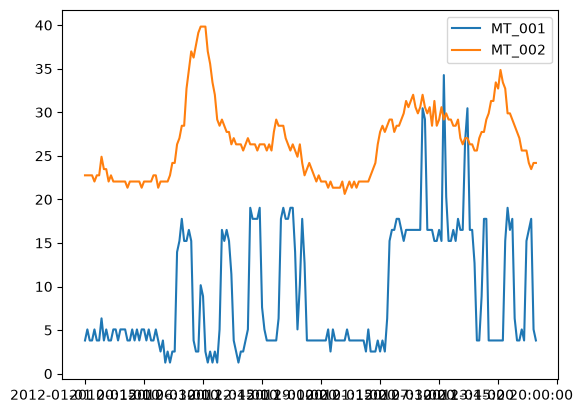

In [6]:
data_example = data.loc['2012-01-01 00:15:00':'2012-01-03 00:00:00'][['MT_001','MT_002']]
data_example.plot()
plt.show()

#### We quickly note that the main difference between the curves is the level (also seen on the means in df.describe()), so we know we will have to somehow normalize the curves, in order for the clustering technique to capture the behaviour of the consumption throughout the day, rather than the overall level.

### Data for the analysis

We focus on 2013 and 2014 because these are the years with lower number of clients having zero demand

In [7]:
data2011 = data.loc['2011-01-01 00:15:00':'2012-01-01 00:00:00']
data2012 = data.loc['2012-01-01 00:15:00':'2013-01-01 00:00:00']
data2013 = data.loc['2013-01-01 00:15:00':'2014-01-01 00:00:00']
data2014 = data.loc['2014-01-01 00:15:00':'2015-01-01 00:00:00']

In [ ]:
# # Check number of days
print(data2011.shape[0]/96)
print(data2012.shape[0]/96)
print(data2013.shape[0]/96)
print(data2014.shape[0]/96)

In [8]:
# See number of clients with 0 demand per year
print(sum(data2011.mean()==0))
print(sum(data2012.mean()==0))
print(sum(data2013.mean()==0))
print(sum(data2014.mean()==0))

210
37
21
1


Remove clients with no demand

In [13]:
clients = data2013.columns
clients_no_demand = clients[data2013.mean()==0] # clients with 0 demand
data_13_14 = pd.concat([data2013, data2014], axis=0) # concatenate 2013 and 2014
data_13_14 = data_13_14.drop(clients_no_demand, axis=1) # drop clients with 0 demand
print(data_13_14.shape)
print(sum(data_13_14.mean()==0)) # check that there are no clients with 0 demand

(70080, 349)
0


## Getting average curves per client

In [14]:
data = data_13_14.copy() # weekdays weekends, data2011, data2012, data2013, data2014

In [15]:
data["hour"] = pd.to_datetime(data.index).hour

In [16]:
data.head(3)

,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,...,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370,hour
2013-01-01 00:15:00,2.538071,22.759602,2.606429,138.211382,63.414634,255.952381,4.522329,239.057239,57.692308,78.494624,...,22300.0,886.075949,1000.000000,16.949153,6.436513,616.330114,76.794658,731.671554,8086.486486,0
2013-01-01 00:30:00,1.269036,22.759602,2.606429,138.211382,63.414634,264.880952,5.652911,228.956229,57.692308,76.344086,...,21000.0,864.978903,909.090909,18.252934,3.510825,564.530290,76.794658,727.272727,8086.486486,0
2013-01-01 00:45:00,2.538071,22.759602,2.606429,134.146341,60.975610,250.000000,5.652911,239.057239,54.195804,76.344086,...,18200.0,860.759494,840.909091,16.949153,5.851375,590.869183,68.447412,730.205279,7848.648649,0


### Getting average curves per client

In [17]:
datagrouped = data.groupby("hour")
average_curves = datagrouped.agg("mean")
average_curves.shape 

(24, 349)

#### The dataframe average_curves contains the 369 typical weekday electric demands

#### We now divide each curve by its mean, so that all curves have mean 1

In [18]:
average_curves_norm = average_curves/(average_curves.mean())

#### Plot the first 2 and last 2 clients

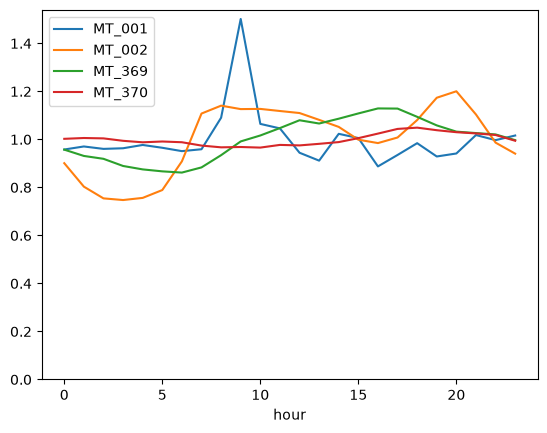

In [19]:
average_curves_norm[['MT_001','MT_002','MT_369','MT_370']].plot()
plt.ylim(bottom=0)
plt.show()

## Clustering Analysis on the average normalized curves

In [20]:
X = average_curves_norm.copy()
X = np.array(X.T) # put it on the right format

## Exercise 1:

a. Using the functions described in Module 2, determine what a convenient number of clusters based on _intertia_ and based on _silhouette_. Justify your choice

b. Make a plot for each cluster, that includes:
    - The number of clients in the cluster (you can put this in the title of the plot)
    - All the curves in the cluster
    - The curve corresponding to the centroid of the cluster (make this curve thicker to distinguish it from the individual curves)
    
You can do 2 separate plots for each cluster if you prefer (one for the individual curves, one for the centroid)

### Answer to question a.

#### Inertia

In [21]:
# Plot inertia of models from 1 to 10 clusters
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 11)]
inertias = [model.inertia_ for model in kmeans_per_k]

In [22]:
# Find the elbow of the inertia values mathematically

from kneed import KneeLocator

def find_elbow(inertias, k_values=None):
    if k_values is None:
        k_values = range(1, len(inertias) + 1)

    if len(k_values) != len(inertias):
        raise ValueError("k_values and inertias must have the same length.")

    elbow = KneeLocator(
        k_values,
        inertias,
        curve="convex",
        direction="decreasing",
    ).elbow

    return int(elbow) if elbow is not None else None

In [23]:
elbow = find_elbow(inertias)
print(f"{elbow = }")

elbow = 4


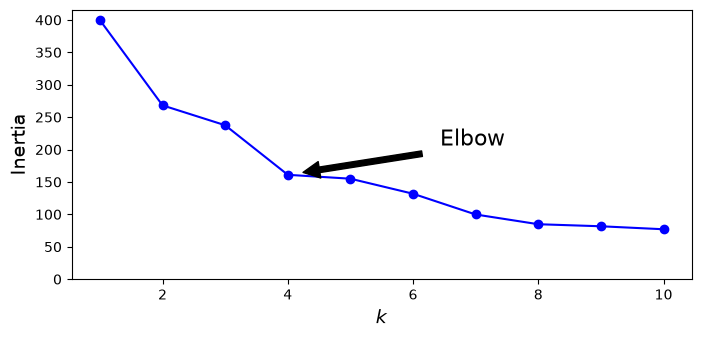

In [24]:
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 11), inertias, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.annotate('Elbow',
             xy=(elbow, inertias[elbow-1]),
             xytext=(0.55, 0.55),
             textcoords='figure fraction',
             fontsize=16,
             arrowprops=dict(facecolor='black', shrink=0.1)
            )
plt.ylim(bottom=0)
plt.show()

Looking at the inertia diagram, it looks like the convenient number of clusters is 4.

However, inertia diagrams can be misleading because inertia has a propensity to go down as k increases. This number can be our baseline.

#### Silhouette diagram

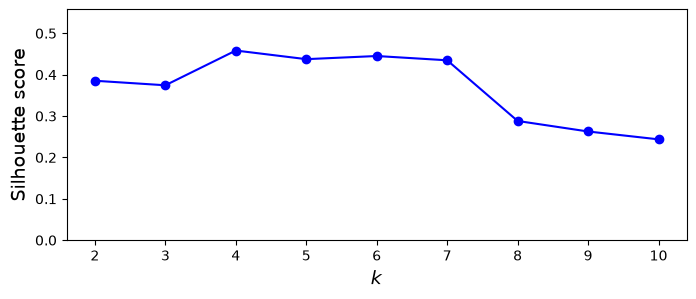

In [25]:
from sklearn.metrics import silhouette_score

def plot_silhouette_scores(X, kmeans_models):
    # Skip k=1; silhouette score requires at least 2 clusters.
    models = kmeans_models[1:]
    k_values = range(2, len(kmeans_models) + 1)
    scores = [silhouette_score(X, model.labels_) for model in models]

    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(k_values, scores, "bo-")
    ax.set_xlabel("$k$", fontsize=14)
    ax.set_ylabel("Silhouette score", fontsize=14)
    ax.set_xticks(k_values)
    ax.set_ylim(bottom=0, top=max(scores) + 0.1)
    plt.show()

    return scores

# Calcualte and plot silhouette scores
silhouette_scores = plot_silhouette_scores(X, kmeans_per_k)

Looks like k = 4 has the best silhouette score, which matches with the elbow value k = 4.

Since silhouette score is calcualted by taking into account intra and inter cluster (nearest external cluster) means and calculating 
how close the score is to the maximum of these two means, it is not affected by the number of target clusters. Hence, it is a more
stable scoring criteria.

However, to make sure we are picking the correct k and not discarding one that explains the variance in the dataset more clearly, let's plot **silhouette diagrams** for each k.

In [26]:
# Plot silhouette diagram

from sklearn.metrics import silhouette_samples
from matplotlib.cm import Spectral
import math

def plot_silhouette_diagram(X, kmeans_models, silhouette_scores):
    # Models are indexed by k - 1; skip k=1 because silhouette requires k >= 2.
    k_values = range(2, len(kmeans_models) + 1)
    ncols = 3
    nrows = math.ceil(len(k_values) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(11, 3 * nrows), squeeze=False
    )

    for k, ax in zip(k_values, axes.flat):
        labels = kmeans_models[k - 1].labels_
        coefficients = silhouette_samples(X, labels)

        padding = len(X) // 30
        pos = padding
        ticks = []

        for cluster_id in range(k):
            cluster_coefficients = np.sort(coefficients[labels == cluster_id])
            end = pos + len(cluster_coefficients)

            ax.fill_betweenx(
                np.arange(pos, end),
                0,
                cluster_coefficients,
                facecolor=Spectral(cluster_id / k),
                edgecolor=Spectral(cluster_id / k),
                alpha=0.7,
            )
            ticks.append(pos + len(cluster_coefficients) // 2)
            pos = end + padding

        ax.set_yticks(ticks, labels=range(k))
        ax.axvline(silhouette_scores[k - 2], color="red", linestyle="--")
        ax.set_title(f"$k={k}$", fontsize=16)

        if k in (3, 5):
            ax.set_ylabel("Cluster")

    # Hide any unused subplot slots.
    for ax in axes.flat[len(k_values):]:
        ax.set_visible(False)

    fig.subplots_adjust(hspace=0.5)
    plt.show()
    return fig, axes

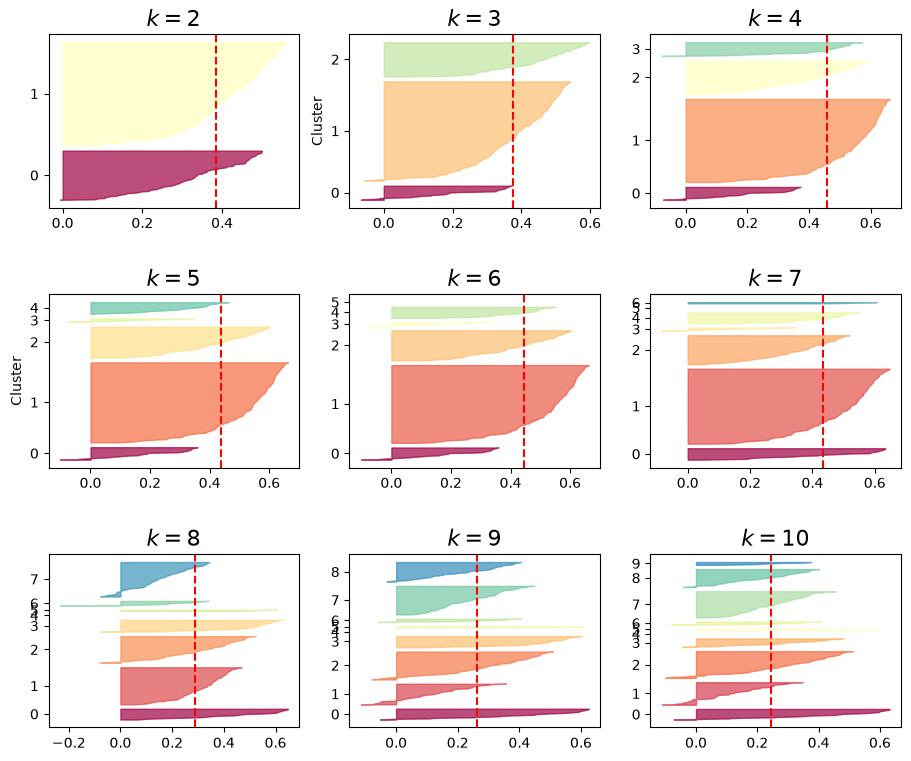

(<Figure size 1100x900 with 9 Axes>,
 array([[<Axes: title={'center': '$k=2$'}>,
         <Axes: title={'center': '$k=3$'}, ylabel='Cluster'>,
         <Axes: title={'center': '$k=4$'}>],
        [<Axes: title={'center': '$k=5$'}, ylabel='Cluster'>,
         <Axes: title={'center': '$k=6$'}>,
         <Axes: title={'center': '$k=7$'}>],
        [<Axes: title={'center': '$k=8$'}>,
         <Axes: title={'center': '$k=9$'}>,
         <Axes: title={'center': '$k=10$'}>]], dtype=object))

In [27]:
plot_silhouette_diagram(X, kmeans_per_k, silhouette_scores)

As seen from the diagram above, k = 4 is not the best candidate because one of its clusters's score is lower than the mean silhouette coeffecient of all of its clusters. Same goes with k = 3, 4, 5, 6, 7.

k = 2, 8, and 9 are promising candidates. All of their cluster widths go past their respective mean silhouette coeffecient. Higher number of clusters also seem to have captured anomalies as evident by the thin cluster(s) shape(s).

k = 10 has too many thin cluster silhouettes which indicates it has overclustered the dataset.

Let's perform some statistical analysis on the standard deviation of each client's values to confirm if there are outliers in the data.

To do this, we can separate the standard deviations of the clients' energy demand from the dataset and check if there are clients who show a very small or large standard deviation. For example, a large standard deviation may mean it is a commercial client among mostly residential clients. A commercial client can be assumed to have a much higher energy footprint during the day.

In [29]:
# Separate standard deviations of the clients and look at its spread
client_std = average_curves_norm.std(axis=0)
client_std.describe()

count    349.000000
mean       0.295314
std        0.138246
min        0.016177
25%        0.226323
50%        0.270726
75%        0.330805
max        1.264350
dtype: float64

In [30]:
# Find how many sample are near 16% (sigma = 2) of the minimum and maximum standard deviation
# *Using the bell curve's 16%-68%-16% spread property

span = client_std.max() - client_std.min()
tolerance = 0.16 * span

near_min = client_std <= client_std.min() + tolerance
near_max = client_std >= client_std.max() - tolerance

print("Clients near minimum:", near_min.sum())
print("Clients near maximum:", near_max.sum())

Clients near minimum: 71
Clients near maximum: 1


Looks like we have at least one anomaly!

Therefore, let's take k = 8 and 9 into consideration along with k = 2 and compare their curves and centroids.

### Answer to question b.


 Make a plot for each cluster, that includes:
    
    
    - The number of clients in the cluster (you can put this in the title of the plot)

    - All the curves in the cluster

    - The curve corresponding to the centroid of the cluster (make this curve thicker to distinguish it from the individual curves)
    
    - You can do 2 separate plots for each cluster if you prefer (one for the individual curves, one for the centroid)

#### Superimpose cluster plots so check whether they are well separated or not
An interesting visualization to start with would be to **superimpose** the clusters with their centroids on a single plot for each k.

We will compare k = 2, 8, and 9

In [31]:
def plot_cluster_profiles(
    X,
    model,
    x_label="Hour of day",
    y_label="Normalized demand",
    group_label="clients",
    xtick_step=2,
):
    X = np.asarray(X)
    labels = model.labels_
    n_clusters = model.n_clusters
    x_values = np.arange(X.shape[1])
    colors = plt.cm.tab10(np.arange(n_clusters))

    fig, ax = plt.subplots(figsize=(11, 6))

    for cluster_id in range(n_clusters):
        curves = X[labels == cluster_id]
        color = colors[cluster_id]

        for curve in curves:
            ax.plot(x_values, curve, color=color, alpha=0.15, linewidth=0.8)

        ax.plot(
            x_values,
            model.cluster_centers_[cluster_id],
            color=color,
            linewidth=3,
            label=f"Cluster {cluster_id + 1} ({len(curves)} {group_label})",
        )

    ax.set(
        title=f"{group_label.capitalize()} demand profiles by cluster",
        xlabel=x_label,
        ylabel=y_label,
        xticks=x_values[::xtick_step],
    )
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

    return fig, ax

In [32]:
k_2, k_8, k_9 = 2, 8, 9

##### k = 2

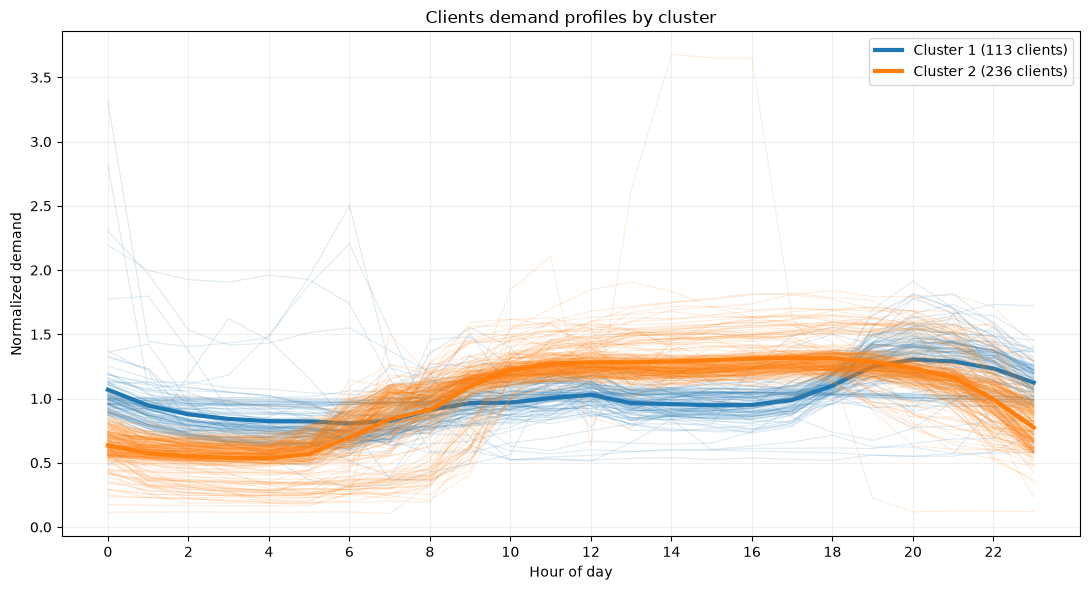

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Clients demand profiles by cluster'}, xlabel='Hour of day', ylabel='Normalized demand'>)

In [33]:
plot_cluster_profiles(X, kmeans_per_k[k_2 - 1])

##### k = 8

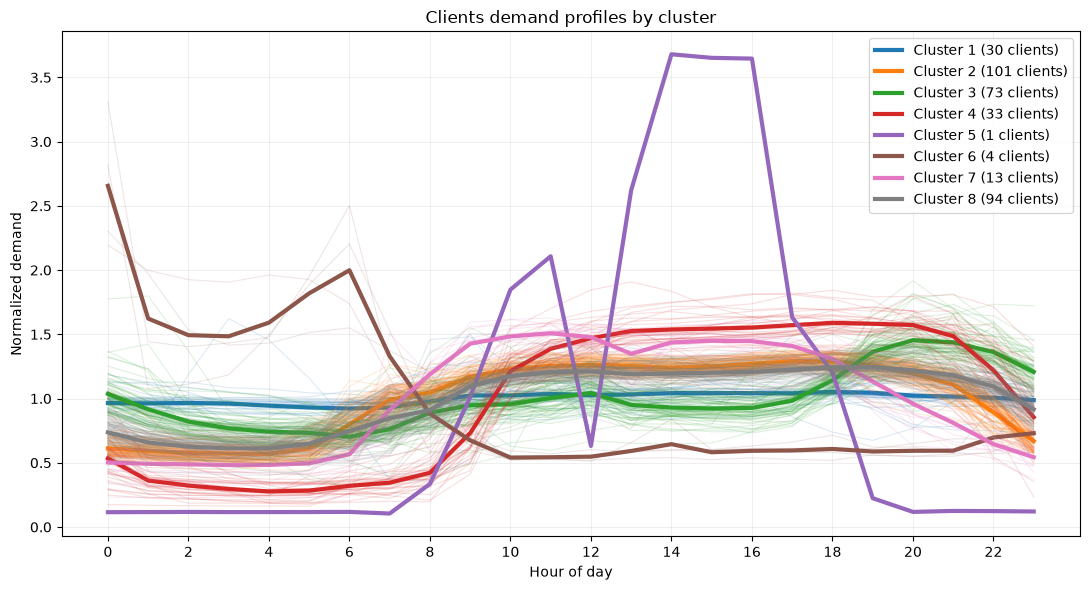

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Clients demand profiles by cluster'}, xlabel='Hour of day', ylabel='Normalized demand'>)

In [34]:
plot_cluster_profiles(X, kmeans_per_k[k_8 - 1])

##### k = 9

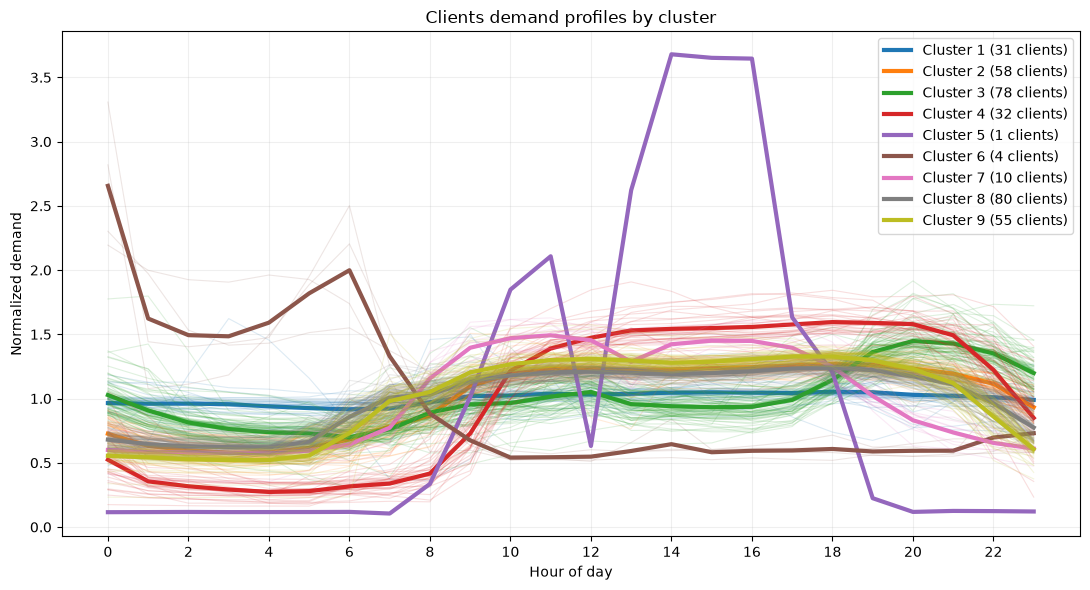

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Clients demand profiles by cluster'}, xlabel='Hour of day', ylabel='Normalized demand'>)

In [35]:
plot_cluster_profiles(X, kmeans_per_k[k_9 - 1])

Looks like k = 2 was not able to capture distinct usage patterns. We will discard it.

k = 8 and 9 shows similar characteristics. Both of them are able to capture regular usage pattern as well as anomalies. However, k = 9 shows more overlapping clusters than k = 8.

So, we can pick k = 8 as our best candidate and plot its daily curves.

#### Plot curves in each cluster (k = 8)

In [36]:
def plot_cluster_curves(
    X,
    model,
    x_label="Hour of day",
    y_label="Normalized demand",
    group_label="clients",
    xtick_step=2,
    xtick_divisor=1,
):
    if xtick_step <= 0 or xtick_divisor <= 0:
        raise ValueError("xtick_step and xtick_divisor must be positive.")

    X = np.asarray(X)
    labels = model.labels_
    x_values = np.arange(X.shape[1])
    plots = []

    for cluster_id in range(model.n_clusters):
        curves = X[labels == cluster_id]
        fig, ax = plt.subplots(figsize=(10, 5))

        for curve in curves:
            ax.plot(x_values, curve, color="steelblue", alpha=0.2, linewidth=0.8)

        ax.plot(
            x_values,
            model.cluster_centers_[cluster_id],
            color="black",
            linewidth=3,
            label="Centroid",
        )

        tick_positions = x_values[::xtick_step]
        tick_labels = [f"{x / xtick_divisor:g}" for x in tick_positions]

        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels)
        ax.set(
            title=f"Cluster {cluster_id + 1} — {len(curves)} {group_label}",
            xlabel=x_label,
            ylabel=y_label,
        )
        ax.legend()
        ax.grid(alpha=0.2)
        fig.tight_layout()
        plots.append((fig, ax))

    plt.show()
    return plots

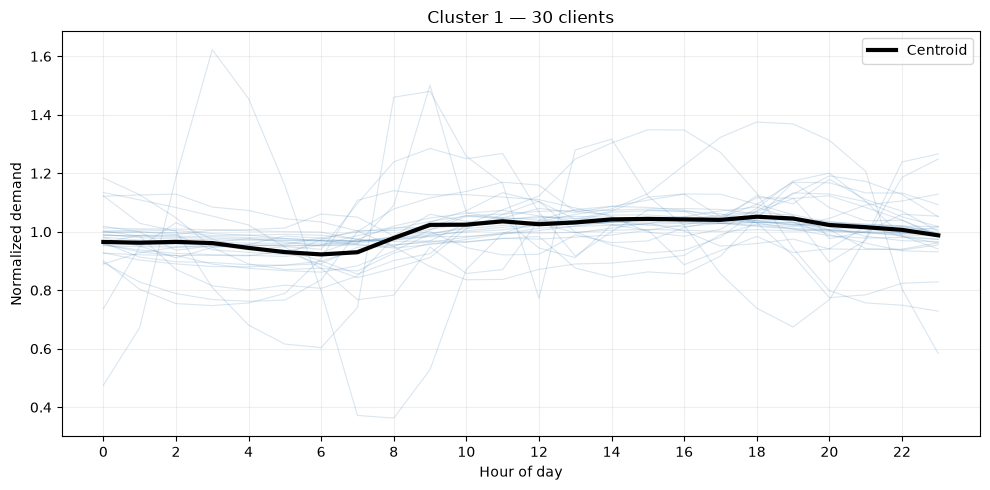

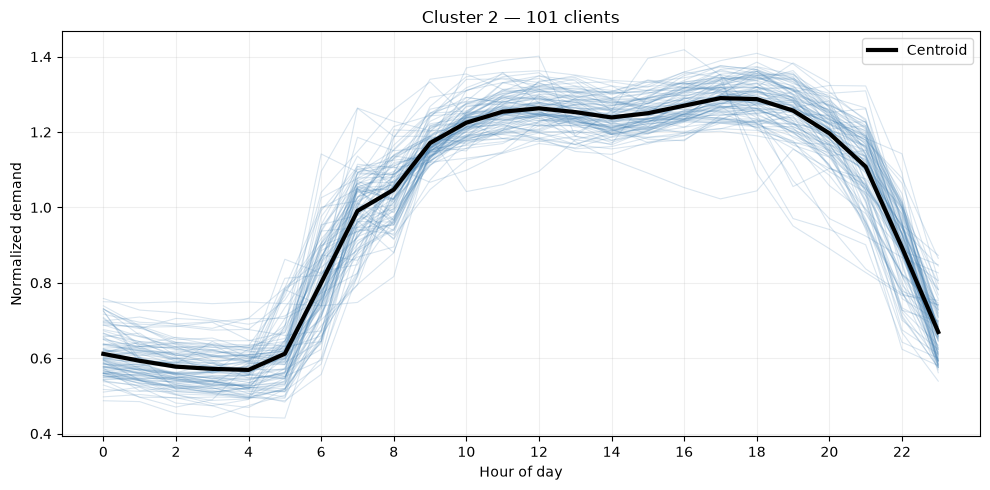

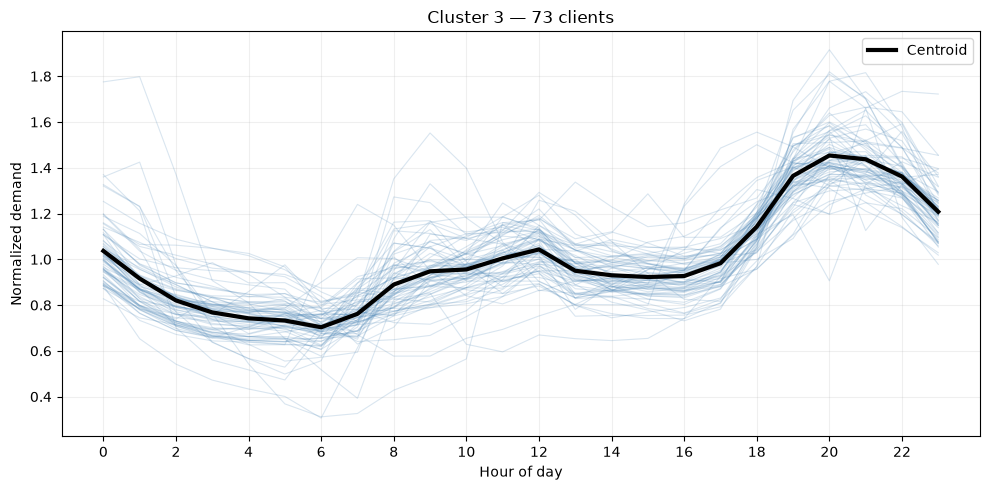

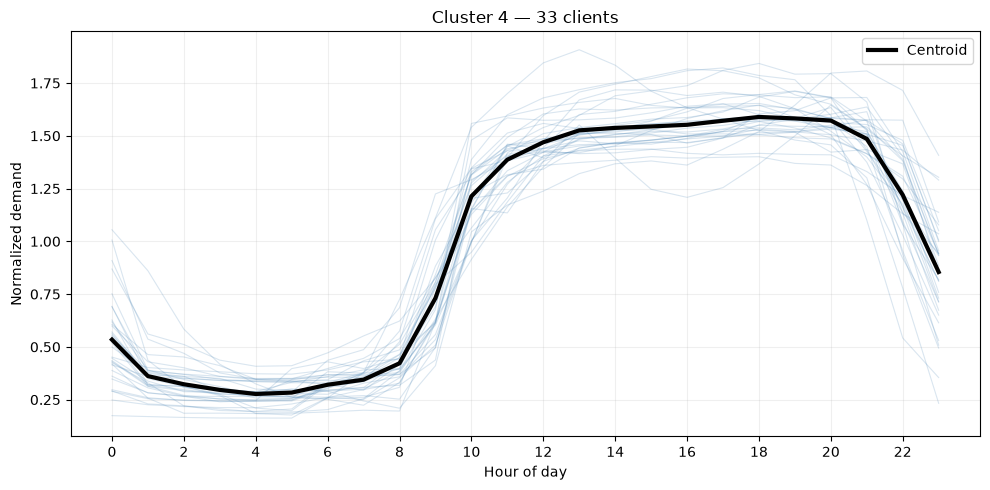

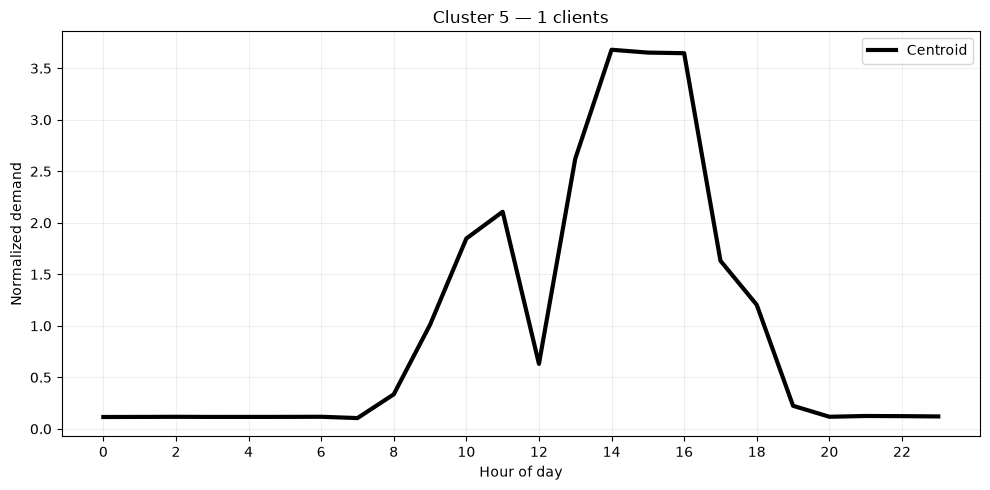

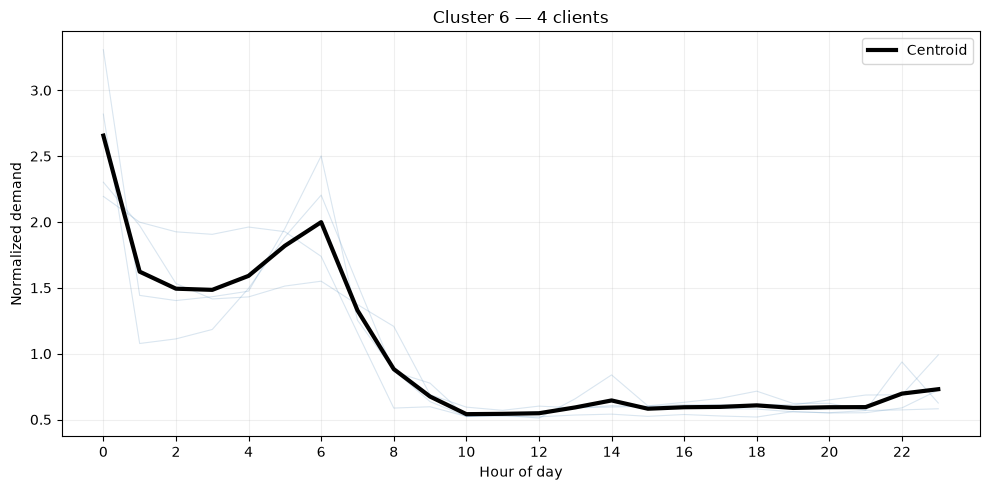

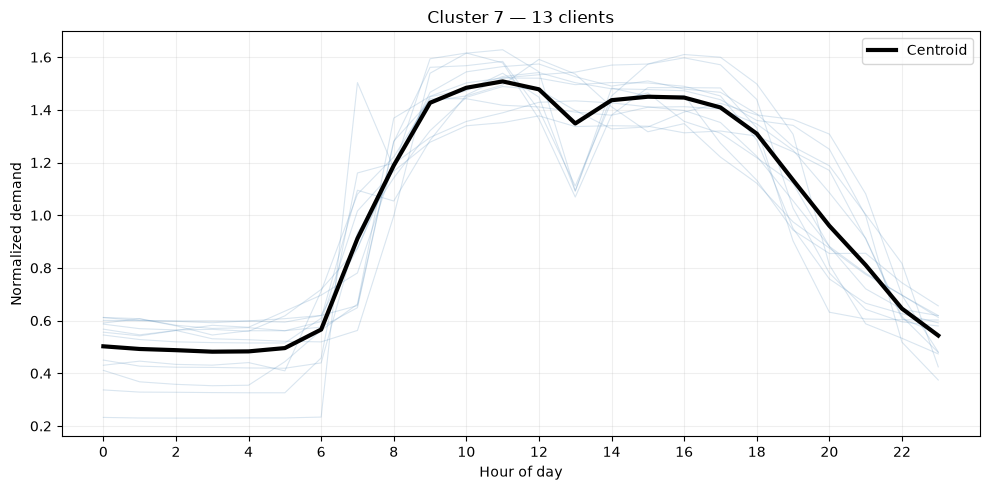

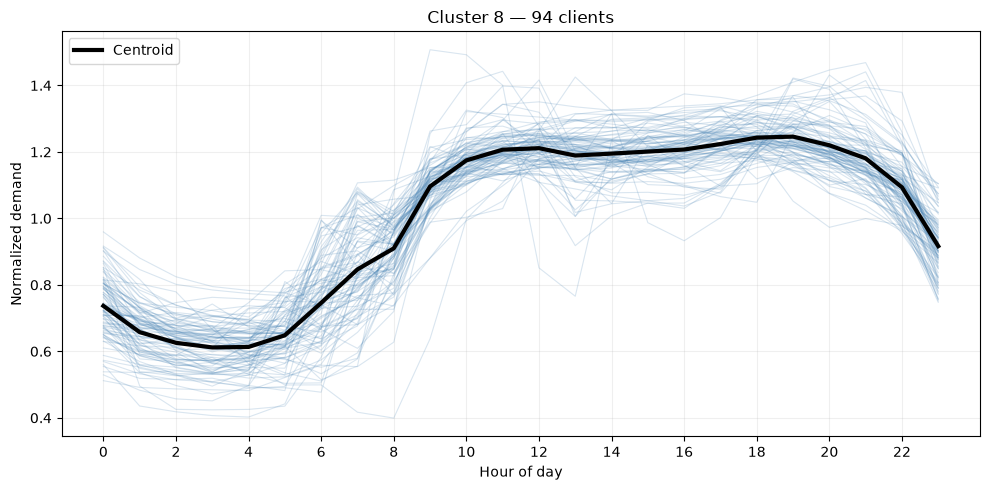

[(<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 1 — 30 clients'}, xlabel='Hour of day', ylabel='Normalized demand'>),
 (<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 2 — 101 clients'}, xlabel='Hour of day', ylabel='Normalized demand'>),
 (<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 3 — 73 clients'}, xlabel='Hour of day', ylabel='Normalized demand'>),
 (<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 4 — 33 clients'}, xlabel='Hour of day', ylabel='Normalized demand'>),
 (<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 5 — 1 clients'}, xlabel='Hour of day', ylabel='Normalized demand'>),
 (<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 6 — 4 clients'}, xlabel='Hour of day', ylabel='Normalized demand'>),
 (<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 7 — 13 clients'}, xlabel='Hour of day', ylabel='Normalized demand'>),


In [37]:
plot_cluster_curves(X, kmeans_per_k[k_8 - 1])

### Verdict
It is clear that k = 8 is the most convenient number of clusters to explain variations in energy demand.

- Its clusters 5, 6, and 7 capture anomalies in energy demands. The client in cluster 5 has the highest peak energy demand among all clients,which may indicate it is a commercial client.

- Clusters 2, 4, and 8 show similar usage patterns but their time of day vary.

  - Clusters 4 and 8 could have been grouped into a single cluster. It can be flagged as a visible weakness of this model.

## Exercises 2

In this exercise you work with the daily curves of 1 single client.

First you create a list of arrays, each array containing a normalized curve for a day. The list contains 730 arrays, one for each of the days of 2013 and 2014.

a. Determine the optimal value for k-means. 

b. What are the clusters that you obtained represent?

### Answer to question a.

In [38]:
client = 'MT_022'
oneClient = data_13_14[client]
X = [] # a list of arrays, each array being a normalized curve for a day
for J in range(2*365):
    # X.extend([np.array(oneClient[J*96:(J+1)*96])]/np.mean(oneClient[J*96:(J+1)*96]))
    curve = np.array(oneClient[J * 96:(J + 1) * 96])
    try:
        X.append(curve / curve.mean())
    except:
        raise ZeroDivisionError(f"Cannot divide by zero. Index {J = }")

### K-means

In [39]:
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 11)]

### Inertia

In [40]:
# Plot inertia of models from 1 to 10 clusters
inertias = [model.inertia_ for model in kmeans_per_k]

In [41]:
# Find elbow
elbow = find_elbow(inertias)
print(f"{elbow = }")

elbow = 2


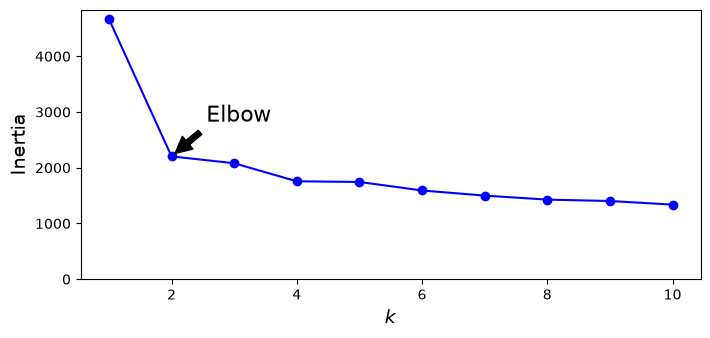

In [42]:
# Plot inertia
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 11), inertias, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.annotate('Elbow',
             xy=(elbow, inertias[elbow - 1]),
             xytext=(25, 25),
             textcoords='offset points',
             fontsize=16,
             arrowprops=dict(facecolor='black', shrink=0.1)
            )
plt.ylim(bottom=0)
plt.show()

#### Silhouette diagram

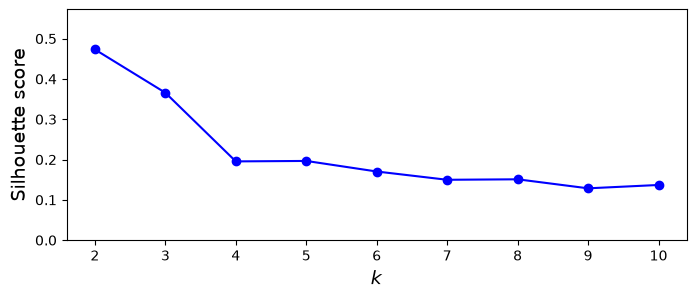

In [43]:
# Calcualte and plot silhouette scores
silhouette_scores = plot_silhouette_scores(X, kmeans_per_k)

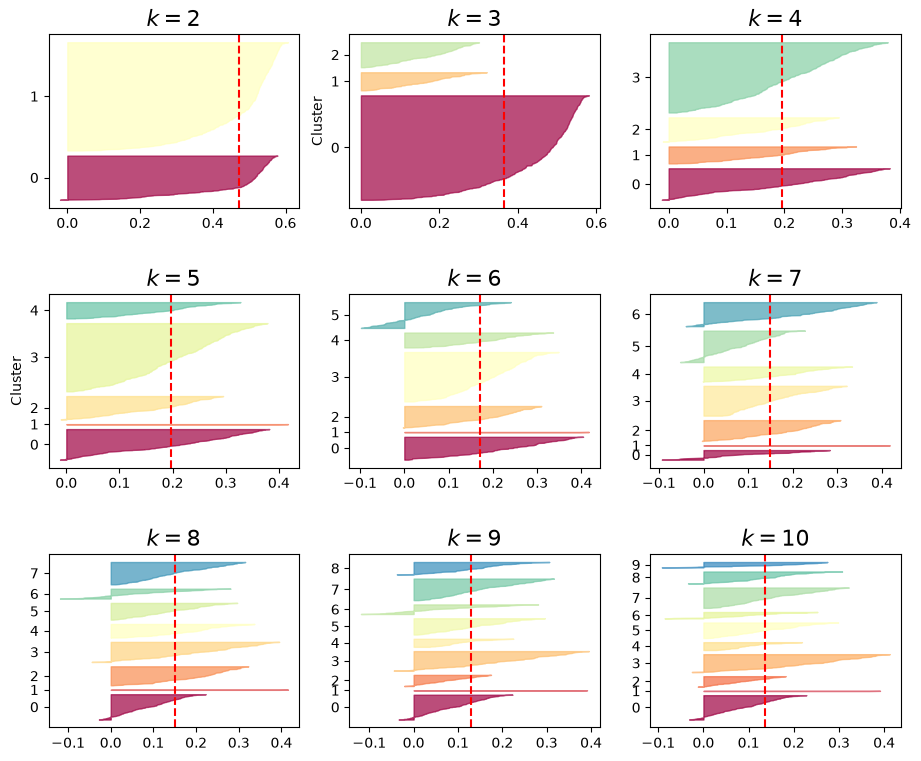

(<Figure size 1100x900 with 9 Axes>,
 array([[<Axes: title={'center': '$k=2$'}>,
         <Axes: title={'center': '$k=3$'}, ylabel='Cluster'>,
         <Axes: title={'center': '$k=4$'}>],
        [<Axes: title={'center': '$k=5$'}, ylabel='Cluster'>,
         <Axes: title={'center': '$k=6$'}>,
         <Axes: title={'center': '$k=7$'}>],
        [<Axes: title={'center': '$k=8$'}>,
         <Axes: title={'center': '$k=9$'}>,
         <Axes: title={'center': '$k=10$'}>]], dtype=object))

In [44]:
plot_silhouette_diagram(X, kmeans_per_k, silhouette_scores)

Looks like k = 2 has a reasonable collection of samples (days) across its two clusters. The silhouette shapes have decent height and width.

However, k = 5 shows more diversity in cluster samples. Their per cluster silhouette scores are also much higher than their mean silhouette coefficient. In addition, it seems to have captured some anomalies in cluster 1.

k = 8 also shows wide shapes. However, its shapes are thin, which might indicate it has more clusters compared to the variance in data.

Lets generate superimposition plots for these three models to find out which one is the most optimal.

#### Superimpose daily curves across all clusters (k = 2, 5, 8)
Discussion is provided after the diagrans.

In [45]:
k_2, k_5, k_8 = 2, 5, 8

##### k = 2

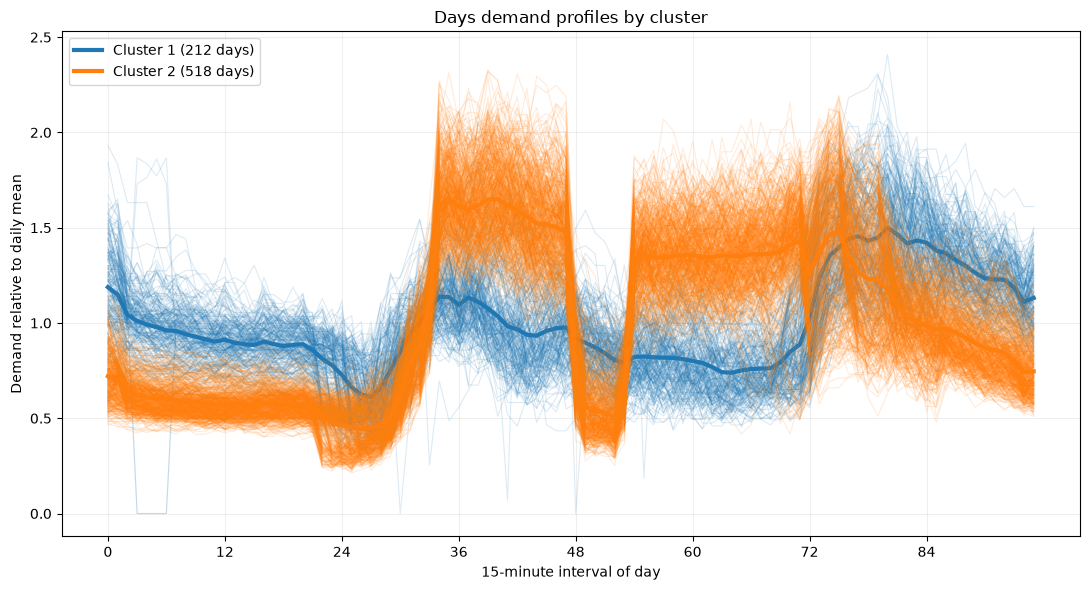

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Days demand profiles by cluster'}, xlabel='15-minute interval of day', ylabel='Demand relative to daily mean'>)

In [46]:
plot_cluster_profiles(
    X,
    kmeans_per_k[k_2 - 1],
    x_label="15-minute interval of day",
    y_label="Demand relative to daily mean",
    group_label="days",
    xtick_step=12,
)

##### k = 5

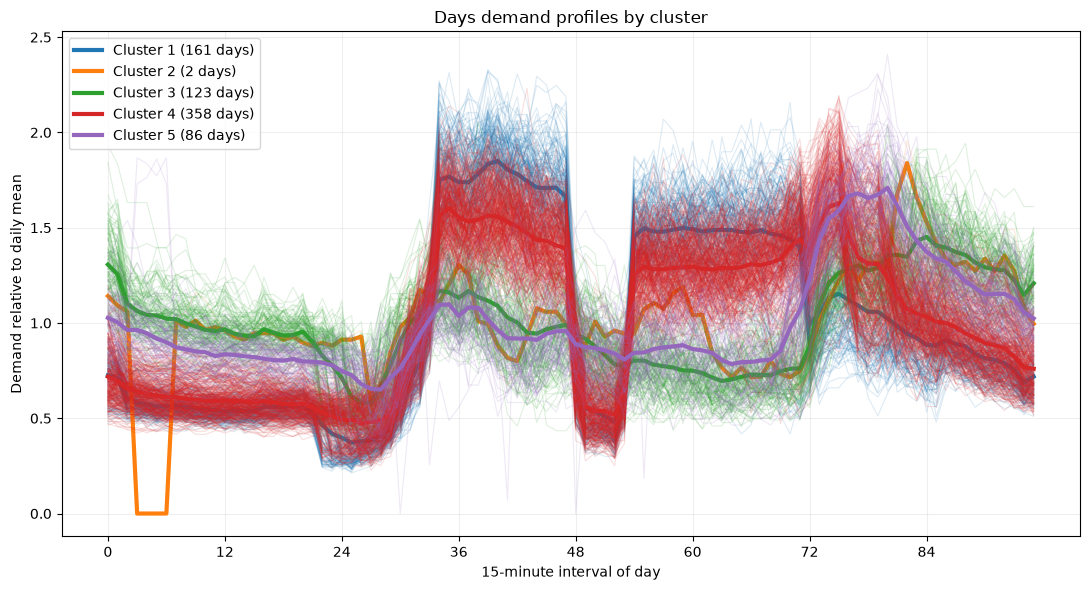

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Days demand profiles by cluster'}, xlabel='15-minute interval of day', ylabel='Demand relative to daily mean'>)

In [47]:
plot_cluster_profiles(
    X,
    kmeans_per_k[k_5 - 1],
    x_label="15-minute interval of day",
    y_label="Demand relative to daily mean",
    group_label="days",
    xtick_step=12,
)

##### k = 8

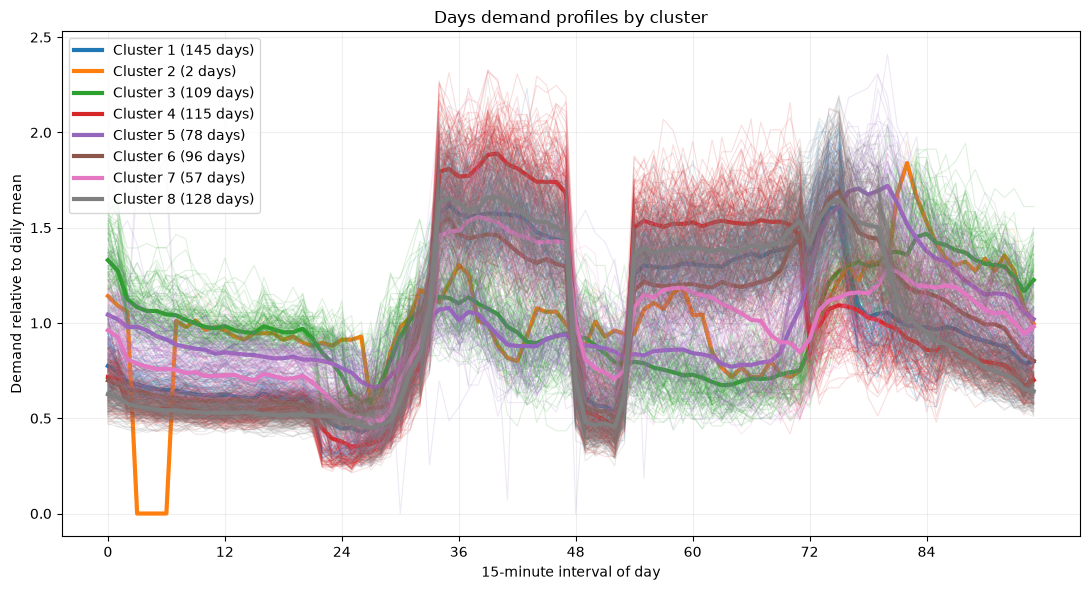

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Days demand profiles by cluster'}, xlabel='15-minute interval of day', ylabel='Demand relative to daily mean'>)

In [48]:
plot_cluster_profiles(
    X,
    kmeans_per_k[k_8 - 1],
    x_label="15-minute interval of day",
    y_label="Demand relative to daily mean",
    group_label="days",
    xtick_step=12,
)

### Discussion
Over the course of 2 years:

With k = 2, the client shows two distinct usage patterns throughout the day. However, this model fails to capture the one anomalous day where usage dropped to zero between 1 am and 2 am. It could have been a power outage.

k = 5 and 8 are able to capture this anomaly. However, their clusters are showing overlapping usage patterns, separated only by the magnitude of demand.

If we ignore the anomalous day, k = 2 is clearly the best model as it perfectlty captures the client's energy usage patterns throughout the day.

### Answer to question b.
Let's plot the daily curves per cluster for k = 2 to check out the curves in the two clusters separately.

#### Plot daily curves per cluster, k = 2

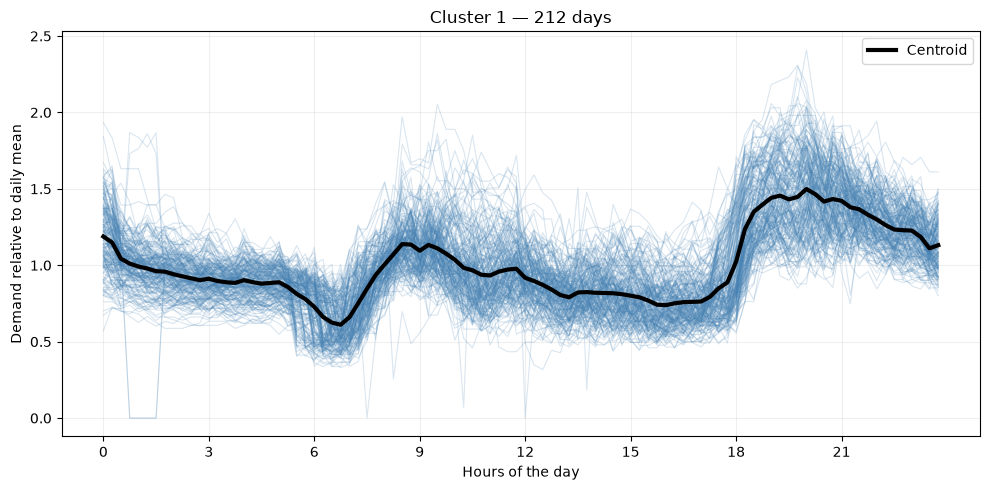

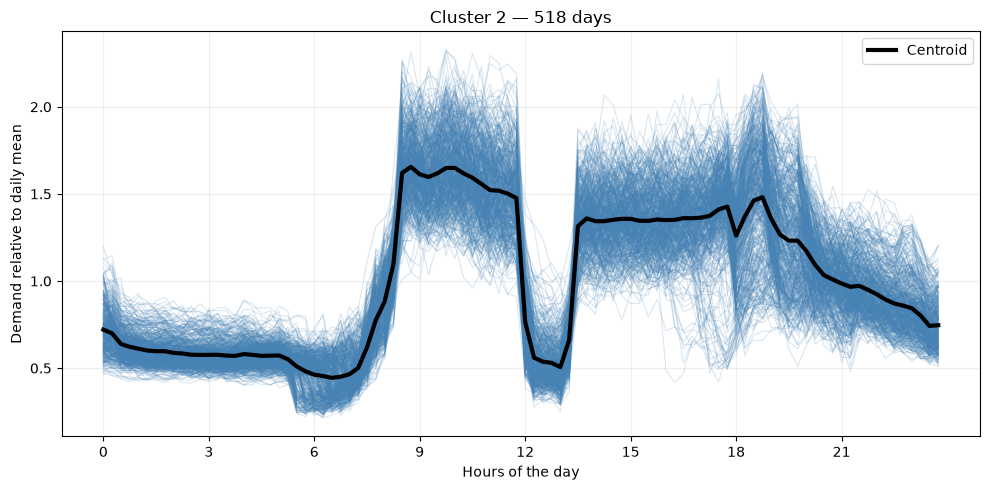

[(<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 1 — 212 days'}, xlabel='Hours of the day', ylabel='Demand relative to daily mean'>),
 (<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 2 — 518 days'}, xlabel='Hours of the day', ylabel='Demand relative to daily mean'>)]

In [49]:
X = np.asarray(X)

plot_cluster_curves(
    X,
    kmeans_per_k[k_2 - 1],
    x_label="Hours of the day",
    y_label="Demand relative to daily mean",
    group_label="days",
    xtick_step=12,
    xtick_divisor=4
)

#### The following cell generates a list of all the days in the two years 2013-2014, which is helpful to answer part (b)

In [50]:
from datetime import date, timedelta

d1 = date(2013, 1, 1)  # start date
d2 = date(2014, 12, 31)  # end date
delta = d2 - d1         # timedelta
daysyear = []
D = {0:'mon', 1:'tue', 2:'wed', 3:'thu', 4:'fri', 5:'sat', 6:'sun'}
for i in range(delta.days + 1):
    daysyear.extend([D[(d1 + timedelta(days=i)).weekday()]+"-"+str(d1 + timedelta(days=i))])

#### The following cell shows you how to do the following: given a list L, and a list of booleans B (True, False), get the sublist of L that corresponds to the True values in B. For example if L=[1,2,3,4] and B=[False,True,True,False], then the results is [2,3]. This is also helpful for part (b)

In [51]:
from itertools import compress
L = [1,2,3,4]
B = [False, True, True, False]
list(compress(L, B))

[2, 3]

In [52]:
from itertools import compress

model = kmeans_per_k[k_2 - 1]  # the model fitted on the 730 daily curves
labels = model.labels_

weekdays = [day.split("-")[0] for day in daysyear]
weekday_order = ["mon", "tue", "wed", "thu", "fri", "sat", "sun"]

for cluster_id in range(model.n_clusters):
    in_cluster = labels == cluster_id

    cluster_days = list(compress(daysyear, in_cluster))
    weekday_counts = (
        pd.Series([weekdays[i] for i in range(len(weekdays)) if in_cluster[i]])
        .value_counts()
        .reindex(weekday_order, fill_value=0)
    )

    print(f"\nCluster {cluster_id+1} — {len(cluster_days)} days")
    print(weekday_counts)


Cluster 1 — 212 days
mon     13
tue     11
wed     10
thu     11
fri     11
sat     52
sun    104
Name: count, dtype: int64

Cluster 2 — 518 days
mon    91
tue    94
wed    95
thu    93
fri    93
sat    52
sun     0
Name: count, dtype: int64


### Discussion
It is clear that cluster 1 represents off days or non-working days and cluster 2 represents working days.

A crucial hint is cluster 2 does not have any Sunday in it, and has half the number of Saturdays compared to the number of Saturdays there can be in 2 years.

It becomes clearer as we look at the curves in the clusters. In cluster 2 (working days), demand is lower than the daily mean from midnight until 6 am. From 6 am, it starts peaking. Peak demand is sustained from 9 am to 12 pm.

At noon, there is a 1-hour dip in demand which can be explained by a lunch break. Then demand peaks again and is sustained until 7 pm. After 7, it starts tapering off.

There is an interesting dip at 6 pm that looks like an oscilation, but I am unable to explain it with the available data.

Cluster 1 shows a typical non-working day pattern where the demand stays near the daily mean with a spike between 8 am and 9 am and another spike around 6 pm. It starts going down at 9 pm, which is closer to bedtime.